# Clasificación de sitios de corte de la proteasa VIH-1

## 1. Objetivo del proyecto

El objetivo es desarrollar un modelo de clasificación binaria que prediga si una secuencia de ocho aminoácidos representa un sitio de corte de la proteasa del VIH-1.

Se utilizarán cuatro conjuntos de datos: 746, 1625, Schilling e Impens. Cada registro contiene una secuencia de ocho aminoácidos y una etiqueta que indica si ocurre el corte.

* `+1`: sitio de corte positivo.
* `-1`: sitio de corte negativo.

El proyecto comprende la integración y exploración de los datos, el análisis de duplicados, la preparación de las variables, el entrenamiento de un modelo y la evaluación de sus resultados.

## 2. Fuente de los datos

Los datos corresponden al conjunto *HIV-1 protease cleavage data*, documentado por Thorsteinn Rögnvaldsson y Liwen You en 2014.

La documentación de referencia describe los cuatro conjuntos y su utilización en investigaciones sobre la predicción de sitios de corte de la proteasa del VIH-1.

## 3. Criterio metodológico

Se utilizará One-Hot Encoding para representar las posiciones de aminoácidos mediante variables binarias. La elección y el procedimiento se documentarán en la sección de preparación de datos.

La columna `source` identificará el conjunto de origen de cada registro. Se utilizará para exploración y trazabilidad, pero no se incluirá entre las variables predictoras del modelo.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Ruta a la carpeta del proyecto
PROJECT_ROOT = Path.cwd().parent

# Carpetas de datos
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

# Comprobar las rutas
print("Raíz del proyecto:", PROJECT_ROOT)
print("Carpeta de datos originales:", DATA_RAW)
print("¿Existe la carpeta raw?:", DATA_RAW.exists())

Raíz del proyecto: C:\Users\luisi\Desktop\Bioinformatica\Data Science\Data science II\hiv-protease-cleavage-classification
Carpeta de datos originales: C:\Users\luisi\Desktop\Bioinformatica\Data Science\Data science II\hiv-protease-cleavage-classification\data\raw
¿Existe la carpeta raw?: True


In [3]:
files = {
    "746": "746Data.txt",
    "1625": "1625Data.txt",
    "Schilling": "schillingData.txt",
    "Impens": "impensData.txt"
}

for source, filename in files.items():
    file_path = DATA_RAW / filename

    print(
        f"{source}: {filename} | "
        f"Existe: {file_path.exists()}"
    )

746: 746Data.txt | Existe: True
1625: 1625Data.txt | Existe: True
Schilling: schillingData.txt | Existe: True
Impens: impensData.txt | Existe: True


## A. Carga e integración de los datos

Los datos se encuentran distribuidos en cuatro archivos de texto: `746Data.txt`, `1625Data.txt`, `schillingData.txt` e `impensData.txt`.

Cada archivo contiene dos columnas sin encabezados: una secuencia de ocho aminoácidos (`sequence`) y una etiqueta binaria (`label`) que indica si la proteasa del VIH-1 corta esa secuencia.

Los cuatro conjuntos se integran verticalmente mediante `pandas.concat()`, reuniendo sus registros en un único DataFrame. Se agrega una columna adicional, `source`, para identificar el conjunto de procedencia de cada observación.

Esta columna se utilizará para la trazabilidad y el análisis exploratorio, pero no se incluirá entre las variables predictoras del modelo. La predicción se basará en la secuencia de aminoácidos.

En esta etapa se conservan los registros originales, sin eliminar duplicados ni modificar las etiquetas. La limpieza se realizará después de inspeccionar la calidad de los datos y las posibles inconsistencias.


In [4]:
# Cargar e integrar los cuatro conjuntos de datos

datasets = []

for source, filename in files.items():

    file_path = DATA_RAW / filename

    df_temp = pd.read_csv(
        file_path,
        header=None,
        names=["sequence", "label"],
        dtype={"sequence": "string", "label": "int64"}
    )

    # Registrar la procedencia de cada observación
    df_temp["source"] = source

    datasets.append(df_temp)

# Unificar los registros en un único DataFrame
df = pd.concat(datasets, ignore_index=True)

print("Dimensiones del dataset integrado:", df.shape)
display(df.head(10))

Dimensiones del dataset integrado: (6590, 3)


,sequence,label,source
0,AAAKFERQ,-1,746
1,AAAMKRHG,-1,746
2,AAAMSSAI,-1,746
3,AAKFERQH,-1,746
4,AAKFESNF,-1,746
5,AAMKRHGL,-1,746
6,AASSSNYC,-1,746
7,AAVLAEAM,1,746
8,ACEGNPYV,-1,746
9,ACKNGQTN,-1,746


In [5]:
# Cantidad de registros por conjunto de origen
print(df["source"].value_counts())

# Distribución de las etiquetas por conjunto
display(pd.crosstab(df["source"], df["label"]))

# Verificar valores faltantes
print("\nValores faltantes por columna:")
print(df.isna().sum())

source
Schilling    3272
1625         1625
Impens        947
746           746
Name: count, dtype: int64


label,-1,1
source,,
1625,1250,375
746,344,402
Impens,798,149
Schilling,2838,434



Valores faltantes por columna:
sequence    0
label       0
source      0
dtype: int64


## B. Resultados de la integración inicial

La integración de los cuatro archivos produjo un DataFrame de **6.590 filas y 3 columnas**: `sequence`, `label` y `source`.

La cantidad de registros por conjunto coincide con la documentación de referencia:

* 746: 746 registros.
* 1625: 1.625 registros.
* Schilling: 3.272 registros.
* Impens: 947 registros.

No se detectaron valores faltantes en las tres columnas.

La distribución de las etiquetas presenta diferencias entre conjuntos. En particular, los conjuntos Schilling, Impens y 1625 tienen más registros negativos que positivos, mientras que en el conjunto 746 las clases están más equilibradas.

Se observó una discrepancia de una observación entre las cantidades por clase informadas en la documentación y las obtenidas para los conjuntos 746 y 1625. Los registros se conservarán sin modificar mientras se realizan las verificaciones de calidad.

Estos resultados corresponden a la inspección inicial; todavía no se han eliminado duplicados ni se han preparado las variables para el modelo.


## C. Validación del formato de las secuencias

Antes de realizar el análisis de duplicados y preparar las variables predictoras, se verifica que todas las secuencias tengan una longitud de ocho caracteres y que utilicen exclusivamente los veinte aminoácidos permitidos por la documentación.

También se comprueba que las etiquetas pertenezcan a las dos clases esperadas: `-1` (no corte) y `+1` (corte).

Estos controles permiten detectar registros con formatos inesperados antes de aplicar las transformaciones necesarias para el modelado.


In [6]:
# Alfabeto de aminoácidos permitido por la documentación
allowed_amino_acids = set("ARNDCQEGHILKMFPSTWYV")

# Longitud de cada secuencia
sequence_lengths = df["sequence"].str.len()

# Secuencias con longitud distinta de 8
invalid_length = sequence_lengths != 8

# Secuencias con caracteres fuera del alfabeto permitido
invalid_alphabet = ~df["sequence"].map(
    lambda seq: set(seq).issubset(allowed_amino_acids)
)

# Etiquetas distintas de -1 y +1
invalid_labels = ~df["label"].isin([-1, 1])

print("Secuencias con longitud incorrecta:", invalid_length.sum())
print("Secuencias con aminoácidos no permitidos:", invalid_alphabet.sum())
print("Etiquetas no válidas:", invalid_labels.sum())

Secuencias con longitud incorrecta: 0
Secuencias con aminoácidos no permitidos: 0
Etiquetas no válidas: 0


## D. Análisis de duplicados

Se analizarán las filas repetidas y las secuencias que aparecen en más de un registro. Este análisis es necesario porque los cuatro conjuntos provienen de fuentes diferentes y la documentación señala que algunos comparten patrones.

Se distinguirán las secuencias repetidas con la misma etiqueta de aquellas que presentan etiquetas diferentes. Las coincidencias se investigarán antes de decidir si corresponde eliminar o conservar registros.

Esta revisión también ayudará a prevenir que una misma secuencia aparezca en los conjuntos de entrenamiento y prueba, lo que podría producir una evaluación demasiado optimista del modelo.


In [7]:
# 1. Filas idénticas en las tres columnas
print(
    "Filas completamente duplicadas:",
    df.duplicated().sum()
)

# 2. Registros cuya secuencia aparece más de una vez
repeated_mask = df.duplicated(
    subset=["sequence"],
    keep=False
)

repeated_sequences = (
    df.loc[repeated_mask]
    .sort_values(["sequence", "source"])
)

print(
    "Registros pertenecientes a secuencias repetidas:",
    repeated_mask.sum()
)

print(
    "Cantidad de secuencias distintas que se repiten:",
    repeated_sequences["sequence"].nunique()
)

display(repeated_sequences.head(20))

Filas completamente duplicadas: 0
Registros pertenecientes a secuencias repetidas: 1500
Cantidad de secuencias distintas que se repiten: 750


,sequence,label,source
939,AAAKFERQ,-1,1625
0,AAAKFERQ,-1,746
898,AAAMKRHG,-1,1625
1,AAAMKRHG,-1,746
1134,AAAMSSAI,1,1625
2,AAAMSSAI,-1,746
771,AAKFERQH,-1,1625
3,AAKFERQH,-1,746
986,AAKFESNF,-1,1625
4,AAKFESNF,-1,746


In [8]:
# Número de etiquetas diferentes para cada secuencia
labels_per_sequence = (
    df.groupby("sequence")["label"]
    .nunique()
)

conflicting_sequences = labels_per_sequence[
    labels_per_sequence > 1
]

print(
    "Secuencias con etiquetas contradictorias:",
    len(conflicting_sequences)
)

# Mostrar sus registros y fuentes
if not conflicting_sequences.empty:
    display(
        df[
            df["sequence"].isin(conflicting_sequences.index)
        ].sort_values(["sequence", "source"])
    )

Secuencias con etiquetas contradictorias: 10


,sequence,label,source
1134,AAAMSSAI,1,1625
2,AAAMSSAI,-1,746
1242,AEAMSQVT,-1,1625
11,AEAMSQVT,1,746
1158,ARVLAQAM,1,1625
67,ARVLAQAM,-1,746
1544,EENFAVEA,-1,1625
3034,EENFAVEA,1,Schilling
1241,FRSGVETT,-1,1625
160,FRSGVETT,1,746


## E. Auditoría de secuencias con etiquetas contradictorias

Se identificaron secuencias que aparecen en más de un conjunto con etiquetas diferentes. Estas observaciones se consideran inconsistencias entre fuentes y no se corregirán automáticamente.

Para cada secuencia se registrarán los conjuntos de procedencia, las etiquetas encontradas y la cantidad de registros asociados. La información permitirá evaluar cada caso individualmente y mantener la trazabilidad de las decisiones metodológicas.

Hasta completar esta revisión, se conservará intacto el DataFrame original. No se asignará una etiqueta definitiva a una secuencia conflictiva sin una justificación documentada.


In [9]:
# Crear una tabla de auditoría de secuencias con etiquetas contradictorias

conflict_sequences = conflicting_sequences.index

label_conflicts = (
    df[df["sequence"].isin(conflict_sequences)]
    .groupby("sequence")
    .agg(
        labels=("label", lambda x: sorted(x.unique().tolist())),
        sources=("source", lambda x: sorted(x.unique().tolist())),
        number_of_records=("sequence", "size")
    )
    .reset_index()
)

display(label_conflicts)

,sequence,labels,sources,number_of_records
0,AAAMSSAI,"[-1, 1]","[1625, 746]",2
1,AEAMSQVT,"[-1, 1]","[1625, 746]",2
2,ARVLAQAM,"[-1, 1]","[1625, 746]",2
3,EENFAVEA,"[-1, 1]","[1625, Schilling]",2
4,FRSGVETT,"[-1, 1]","[1625, 746]",2
5,GRINVALV,"[-1, 1]","[1625, 746]",2
6,QEEMLQRE,"[-1, 1]","[1625, Schilling]",2
7,SGVFSVNG,"[-1, 1]","[1625, 746]",2
8,SGVYQLSA,"[-1, 1]","[1625, 746]",2
9,VEEGIVLG,"[-1, 1]","[Impens, Schilling]",2


In [10]:
# Frecuencia de cada secuencia en el conjunto combinado

sequence_frequency = (
    df.groupby("sequence")
    .agg(
        number_of_records=("sequence", "size"),
        number_of_labels=("label", "nunique"),
        number_of_sources=("source", "nunique")
    )
    .reset_index()
)

print("Frecuencia de aparición de las secuencias:")
display(
    sequence_frequency["number_of_records"]
    .value_counts()
    .sort_index()
)

print(
    "\nSecuencias presentes en tres o más registros:",
    (sequence_frequency["number_of_records"] >= 3).sum()
)

Frecuencia de aparición de las secuencias:


number_of_records
1    5090
2     750
Name: count, dtype: Int64


Secuencias presentes en tres o más registros: 0


## F. Criterios para construir el conjunto de modelado

### F.1. Duplicados y etiquetas contradictorias

La integración de los cuatro conjuntos identificó 750 secuencias que aparecen dos veces. De ellas, 740 tienen la misma etiqueta en ambas apariciones, mientras que 10 presentan etiquetas contradictorias entre las fuentes.

Estas discrepancias están documentadas en la literatura científica. Rögnvaldsson, You y Garwicz (2015) describen conflictos entre los conjuntos 746, 1625, Schilling e Impens, relacionados con resultados experimentales contradictorios, sitios de corte inferidos y experimentales, e interpretaciones diferentes de cortes débiles.

Por lo tanto, no se asumirán errores experimentales en todos los casos ni se asignarán etiquetas correctas sin evidencia suficiente.

### F.2. Decisión metodológica

Se adoptarán los siguientes criterios:

1. **Conservar el DataFrame original:** el conjunto integrado `df` no se modificará, para mantener la trazabilidad de los registros originales.
2. **Excluir las secuencias con etiquetas contradictorias:** se retirarán las diez secuencias ambiguas del conjunto de modelado, ya que no se dispone de evidencia suficiente para establecer una etiqueta definitiva.
3. **Reducir las repeticiones con etiquetas coincidentes:** se conservará una única observación por secuencia y etiqueta. Se mantendrá la información de procedencia en la columna `source`.
4. **Evitar el solapamiento entre entrenamiento y prueba:** cada secuencia aparecerá una sola vez en el conjunto de modelado antes de realizar la división de datos.
5. **Excluir `source` de las variables predictoras:** esta columna se utilizará para trazabilidad y análisis exploratorio, pero el modelo utilizará únicamente la secuencia de aminoácidos.

Esta estrategia está respaldada por el tratamiento de los datos descrito por *The importance of physicochemical characteristics and nonlinear classifiers in determining HIV-1 protease specificity*, que informa la eliminación de los ejemplares conflictivos y la reducción de las secuencias repetidas a una sola instancia, obteniendo 5.830 ejemplares únicos.

La cantidad final de registros y la distribución de las clases se verificarán mediante código antes de continuar con el modelado.

### F.3. Referencias bibliográficas

* Rögnvaldsson, T., You, L., & Garwicz, D. (2015). *State of the art prediction of HIV-1 protease cleavage sites*. Bioinformatics, 31(8), 1204–1210. https://doi.org/10.1093/bioinformatics/btu810

* *The importance of physicochemical characteristics and nonlinear classifiers in determining HIV-1 protease specificity*. (2016). PMC: https://pmc.ncbi.nlm.nih.gov/articles/PMC4879986/


In [11]:
# Identificar secuencias asociadas a más de una etiqueta

labels_per_sequence = (
    df.groupby("sequence")["label"]
    .nunique()
)

conflicting_sequences = labels_per_sequence[
    labels_per_sequence > 1
].index

print(
    "Cantidad de secuencias con etiquetas contradictorias:",
    len(conflicting_sequences)
)

Cantidad de secuencias con etiquetas contradictorias: 10


In [12]:
# Excluir secuencias con etiquetas contradictorias
df_without_conflicts = df[
    ~df["sequence"].isin(conflicting_sequences)
].copy()

# Consolidar secuencias repetidas con la misma etiqueta.
# Se conserva la procedencia de todos los registros.
df_model = (
    df_without_conflicts
    .groupby(["sequence", "label"], as_index=False)
    .agg(
        source=(
            "source",
            lambda sources: " | ".join(sorted(set(sources)))
        )
    )
)

print("Registros originales:", len(df))
print("Registros tras excluir conflictos:", len(df_without_conflicts))
print("Registros finales para modelado:", len(df_model))
print(
    "Secuencias duplicadas en el conjunto final:",
    df_model["sequence"].duplicated().sum()
)

Registros originales: 6590
Registros tras excluir conflictos: 6570
Registros finales para modelado: 5830
Secuencias duplicadas en el conjunto final: 0


In [13]:
# Verificar las etiquetas y la calidad del conjunto final

print("Dimensiones finales:", df_model.shape)

print("\nDistribución de etiquetas:")
print(df_model["label"].value_counts().sort_index())

print("\nDistribución porcentual:")
print(
    (
        df_model["label"].value_counts(normalize=True).sort_index()
        * 100
    ).round(2)
)

print("\nValores faltantes:")
print(df_model.isna().sum())

print(
    "\n¿Todas las secuencias son únicas?:",
    df_model["sequence"].is_unique
)

Dimensiones finales: (5830, 3)

Distribución de etiquetas:
label
-1    4839
 1     991
Name: count, dtype: int64

Distribución porcentual:
label
-1    83.0
 1    17.0
Name: proportion, dtype: float64

Valores faltantes:
sequence    0
label       0
source      0
dtype: int64

¿Todas las secuencias son únicas?: True


## G. Estrategia de preprocesamiento y reproducibilidad

### G.1. Decisión metodológica

Para construir un flujo de modelado reproducible, se utilizará un pipeline de `scikit-learn` que integre la codificación de las secuencias y el clasificador.

La preparación de los datos se organizará en dos etapas:

1. **Preparación del conjunto de modelado:** se conservará una única observación por secuencia, se excluirán las secuencias con etiquetas contradictorias y se mantendrá la procedencia de los registros para su trazabilidad. Estas decisiones ya fueron documentadas y verificadas.
2. **Preprocesamiento y modelado:** cada secuencia se representará mediante sus ocho posiciones, y cada posición se codificará mediante One-Hot Encoding dentro del pipeline. El clasificador recibirá la matriz numérica resultante.

La columna `source` no se utilizará como variable predictora, ya que identifica la procedencia de los registros y no forma parte de la representación de la secuencia que se desea evaluar.

### G.2. Justificación del pipeline

La integración del preprocesamiento y el clasificador permite aplicar de forma consistente las mismas transformaciones durante el entrenamiento, la evaluación y las predicciones sobre nuevas observaciones.

Además, facilita la comparación entre distintos algoritmos y reduce el riesgo de errores al repetir manualmente las transformaciones.

Se realizará una división estratificada de los datos en conjuntos de entrenamiento y prueba antes de ajustar el pipeline. El conjunto de prueba se reservará para la evaluación final. El preprocesamiento y el entrenamiento se ajustarán utilizando únicamente los datos de entrenamiento.

### G.3. Técnica de codificación

Se utilizará One-Hot Encoding para representar los aminoácidos de cada posición mediante variables binarias. Dado que las secuencias tienen ocho posiciones y se consideran los 20 aminoácidos estándar, la representación tendrá 160 variables predictoras.

Esta codificación no asigna un orden numérico artificial a los aminoácidos y conserva la identidad del aminoácido presente en cada posición.

### G.4. Referencia técnica

* Scikit-learn. *Pipelines and composite estimators*. Documentación oficial: https://scikit-learn.org/stable/modules/compose.html
* Scikit-learn. *Common pitfalls and recommended practices*. Documentación oficial: https://scikit-learn.org/stable/common_pitfalls.html


In [14]:
# Separar cada secuencia en sus ocho posiciones
sequence_positions = df_model["sequence"].apply(
    lambda sequence: list(sequence)
)

# Crear una columna por posición de la secuencia
X_sequences = pd.DataFrame(
    sequence_positions.tolist(),
    columns=[
        f"pos_{position}"
        for position in range(1, 9)
    ],
    index=df_model.index
)

# Definir la variable objetivo
y = df_model["label"].copy()

print("Dimensiones de las secuencias:", X_sequences.shape)
print("\nPrimeras observaciones:")
display(X_sequences.head())

print("\nDistribución de etiquetas:")
print(y.value_counts())

Dimensiones de las secuencias: (5830, 8)

Primeras observaciones:


,pos_1,pos_2,pos_3,pos_4,pos_5,pos_6,pos_7,pos_8
0,A,A,A,A,A,P,A,K
1,A,A,A,A,P,A,K,V
2,A,A,A,E,L,G,A,R
3,A,A,A,G,K,S,G,G
4,A,A,A,K,F,E,R,Q



Distribución de etiquetas:
label
-1    4839
 1     991
Name: count, dtype: int64


### H. División de los datos

Se dividirá el conjunto de datos en entrenamiento (80 %) y prueba (20 %). La división será estratificada según la variable objetivo para mantener una distribución de clases similar en ambos conjuntos.

Se fijará `random_state=42` para garantizar que la división pueda reproducirse. El conjunto de prueba permanecerá reservado para evaluar el rendimiento final de los modelos.

El preprocesamiento mediante One-Hot Encoding se ajustará dentro de cada pipeline utilizando los datos de entrenamiento, evitando utilizar información del conjunto de prueba durante el ajuste.


In [16]:
from sklearn.model_selection import train_test_split

# División estratificada de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X_sequences,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nProporciones de clases en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nProporciones de clases en prueba:")
print(y_test.value_counts(normalize=True).round(3))

Entrenamiento: (4664, 8)
Prueba: (1166, 8)

Proporciones de clases en entrenamiento:
label
-1    0.83
 1    0.17
Name: proportion, dtype: float64

Proporciones de clases en prueba:
label
-1    0.83
 1    0.17
Name: proportion, dtype: float64


## I. Pipeline de preprocesamiento y modelado

Se utilizará un pipeline de `scikit-learn` que integra la codificación One-Hot de las ocho posiciones de cada secuencia y un modelo de regresión logística.

Debido al desbalance de clases (83 % frente a 17 %), se utilizará `class_weight="balanced"` para asignar mayor peso a la clase minoritaria durante el entrenamiento.

El pipeline permite aplicar las mismas transformaciones durante el entrenamiento y la predicción, manteniendo un flujo reproducible. El conjunto de prueba se reservará para la evaluación final.


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Pipeline de preprocesamiento y clasificación
logistic_pipeline = Pipeline([
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore")
    ),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )
])

# Entrenar con los datos de entrenamiento
logistic_pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")

Pipeline entrenado correctamente.


## J. Evaluación del modelo

El rendimiento se evaluará sobre el conjunto de prueba mediante métricas de clasificación y una matriz de confusión.

Se analizarán precision, recall y F1-score para ambas clases, junto con la balanced accuracy. Se prestará especial atención al recall de la clase +1, para evaluar la capacidad del modelo de identificar las secuencias positivas.


In [18]:
from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generar predicciones sobre el conjunto de prueba
y_pred = logistic_pipeline.predict(X_test)

# Métricas generales
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, y_pred):.4f}"
)

# Métricas por clase
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[-1, 1],
        target_names=["Clase -1", "Clase +1"],
        zero_division=0
    )
)

Accuracy: 0.9151
Balanced accuracy: 0.9167

Reporte de clasificación:
              precision    recall  f1-score   support

    Clase -1       0.98      0.91      0.95       968
    Clase +1       0.69      0.92      0.79       198

    accuracy                           0.92      1166
   macro avg       0.83      0.92      0.87      1166
weighted avg       0.93      0.92      0.92      1166



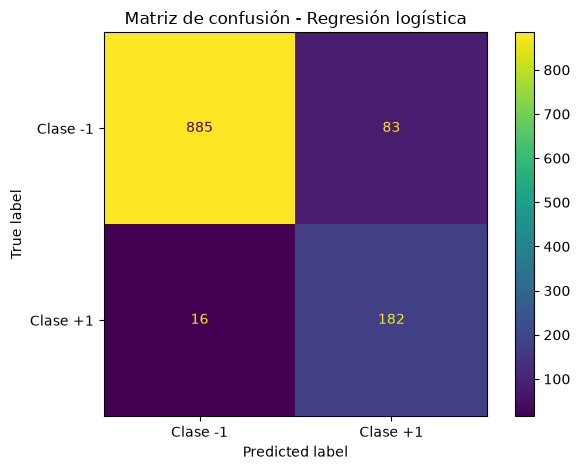

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Clase -1", "Clase +1"]
)

disp.plot()
plt.title("Matriz de confusión - Regresión logística")
plt.tight_layout()
plt.show()

## K. Interpretación de las métricas y resultados

### K.1. Métricas principales

El modelo de regresión logística obtuvo una accuracy de 91,51 % y una balanced accuracy de 91,67 %. Estos resultados indican un buen rendimiento general en el conjunto de prueba. Sin embargo, dado que el 83 % de las observaciones pertenece a la clase -1 y el 17 % a la clase +1, la accuracy no debe interpretarse de forma aislada.

En este problema, se prioriza el análisis del **recall de la clase +1**, ya que permite evaluar qué proporción de las secuencias positivas reales es identificada por el modelo. Si el objetivo es detectar posibles sitios de corte de la proteasa, los falsos negativos representan secuencias positivas que el modelo no logra identificar.

El recall de la clase +1 fue de 91,92 %: el modelo identificó 182 de las 198 secuencias positivas del conjunto de prueba y clasificó incorrectamente 16 como negativas.

### K.2. Precision y falsos positivos

La precision de la clase +1 fue de 68,68 %. De las 265 secuencias predichas como positivas, 182 correspondían efectivamente a esa clase y 83 eran negativas.

Esto indica que, aunque el modelo recupera una proporción elevada de las secuencias positivas, una parte de sus predicciones positivas es incorrecta. Por lo tanto, la precision también es relevante: permite evaluar la confiabilidad de las predicciones positivas y cuantificar la proporción de falsos positivos entre ellas.

En un contexto de investigación, los falsos positivos podrían generar candidatos que requieran análisis adicionales. No obstante, el costo concreto de estos errores depende del uso posterior del modelo y no puede determinarse únicamente a partir de este ejercicio.

### K.3. F1-score y evaluación conjunta

El F1-score de la clase +1 fue de 0,79. Esta métrica combina precision y recall mediante su media armónica, por lo que resulta útil para resumir el equilibrio entre la detección de secuencias positivas y la proporción de predicciones positivas correctas.

La balanced accuracy fue de 91,67 %, calculada como el promedio del recall de ambas clases. Su valor, cercano a la accuracy, indica que el buen rendimiento general no se explica únicamente por la clase mayoritaria.

### K.4. Matriz de confusión

La matriz de confusión mostró:

* **885 verdaderos negativos:** secuencias de clase -1 correctamente identificadas.
* **182 verdaderos positivos:** secuencias de clase +1 correctamente identificadas.
* **83 falsos positivos:** secuencias de clase -1 clasificadas como +1.
* **16 falsos negativos:** secuencias de clase +1 clasificadas como -1.

Estos resultados permiten observar los tipos de error que la accuracy por sí sola no distingue.

### K.5. Conclusión y limitaciones

El modelo obtuvo un buen rendimiento inicial, con una accuracy de 91,51 % y un recall de 91,92 % para la clase positiva. La principal limitación observada es la precision de esa clase, de 68,68 %, debido a la cantidad de falsos positivos.

La métrica prioritaria depende del objetivo de uso: si se busca recuperar la mayor cantidad posible de sitios de corte, el recall de la clase +1 es especialmente importante; si se busca reducir la cantidad de candidatos positivos incorrectos, cobra mayor importancia la precision. El F1-score permite resumir el equilibrio entre ambas.

Estos resultados corresponden a una única división estratificada de entrenamiento y prueba. Además, la ausencia de secuencias idénticas entre ambos conjuntos no garantiza la ausencia de secuencias biológicamente similares. Por ello, los resultados deben considerarse una evaluación inicial y no una garantía de generalización a secuencias nuevas o evolutivamente diferentes.
